<div style="background: linear-gradient(135deg, #42a5f5, #ef5350); padding: 25px; border-radius: 12px; text-align: center; color: white; box-shadow: 0 4px 15px rgba(0,0,0,0.2); animation: float 3s ease-in-out infinite;">

# ⚙️ Predictive Maintenance Classification

![Status](https://img.shields.io/badge/Status-Active-red?style=for-the-badge)  
![Stage 1 Accuracy](https://img.shields.io/badge/Stage%201%20Accuracy-98.9%25-brightgreen?style=for-the-badge)  
![Stage 2 Accuracy](https://img.shields.io/badge/Stage%202%20Accuracy-92.8%25-blue?style=for-the-badge)

*Predicting equipment failures with Machine Learning for better efficiency.*

</div>

<style>
@keyframes float {
    0% { transform: translateY(0); }
    50% { transform: translateY(-8px); }
    100% { transform: translateY(0); }
}
</style>


## Dataset Overview

**Source:** [Predictive Maintenance Dataset on Kaggle](https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification)

**Shape:**  

- **Rows:** 10,000  

- **Columns:** 14 (13 features + 1 target)

**Target Variable:**  

- `Failure Type` – Indicates whether the machine experienced a failure and its type.

**Key Features:**

- `UID`: Unique identifier for each data point.
- `Product ID`: Encodes product type and variant.
- `Air temperature [K]`: Environmental air temperature.
- `Process temperature [K]`: Internal process temperature.
- `Rotational speed [rpm]`: Machine rotational speed.
- `Torque [Nm]`: Load applied to the machine.
- `Tool wear [min]`: Duration of tool usage.
- `Machine Failure`: Binary indicator if any failure occurred.

- Additional flags for specific failure types:  
  - `TWF`: Tool wear failure  
  - `HDF`: Heat dissipation failure  
  - `PWF`: Power failure  
  - `OSF`: Overstrain failure  
  - `RNF`: Random failure


<h2 style="color:#1976d2;">1. Import the Libraries</h2>



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler,RobustScaler,MinMaxScaler
from datasist.structdata import detect_outliers
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_validate
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import label_binarize
import warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_curve,
    auc
)
from sklearn.model_selection import cross_validate, StratifiedKFold
import joblib
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import VotingClassifier


<h2 style="color:#1976d2;">2. Load Dataset</h2>


In [2]:
df = pd.read_csv('predictive_maintenance.csv')

<h2 style="color:#1976d2;">3. Exploratory Data Analysis</h2>


In [3]:
df[df["Target"]==1].head(-1)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
50,51,L47230,L,298.9,309.1,2861,4.6,143,1,Power Failure
69,70,L47249,L,298.9,309.0,1410,65.7,191,1,Power Failure
77,78,L47257,L,298.8,308.9,1455,41.3,208,1,Tool Wear Failure
160,161,L47340,L,298.4,308.2,1282,60.7,216,1,Overstrain Failure
161,162,L47341,L,298.3,308.1,1412,52.3,218,1,Overstrain Failure
...,...,...,...,...,...,...,...,...,...,...
9667,9668,L56847,L,299.2,310.3,1352,48.9,238,1,Overstrain Failure
9758,9759,L56938,L,298.6,309.8,2271,16.2,218,1,Tool Wear Failure
9764,9765,L56944,L,298.5,309.5,1294,66.7,12,1,Power Failure
9822,9823,L57002,L,298.5,309.4,1360,60.9,187,1,Overstrain Failure


In [4]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64

In [5]:
df.duplicated().sum()

0

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


In [7]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [8]:
df.drop(columns=['UDI', 'Product ID'], inplace=True)

In [9]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,M,298.1,308.6,1551,42.8,0,0,No Failure
1,L,298.2,308.7,1408,46.3,3,0,No Failure
2,L,298.1,308.5,1498,49.4,5,0,No Failure
3,L,298.2,308.6,1433,39.5,7,0,No Failure
4,L,298.2,308.7,1408,40.0,9,0,No Failure


In [10]:
df.nunique()

Type                         3
Air temperature [K]         93
Process temperature [K]     82
Rotational speed [rpm]     941
Torque [Nm]                577
Tool wear [min]            246
Target                       2
Failure Type                 6
dtype: int64

<h2 style="color:#1976d2;">4. Feature Engineering</h2>


In [11]:
df['temperature_difference']=df['Process temperature [K]']-df['Air temperature [K]']

In [12]:
# Calculate Mechanical Power
# Mechanical Power (P) = Torque (T) * Angular Velocity (ω)
# Angular Velocity (ω) = (Rotational Speed [rpm] * 2 * π
df['Mechanical Power [W]']=np.round((df['Torque [Nm]']*df['Rotational speed [rpm]']* 2 * np.pi) / 60,4)

In [13]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type,temperature_difference,Mechanical Power [W]
0,M,298.1,308.6,1551,42.8,0,0,No Failure,10.5,6951.5906
1,L,298.2,308.7,1408,46.3,3,0,No Failure,10.5,6826.7227
2,L,298.1,308.5,1498,49.4,5,0,No Failure,10.4,7749.3875
3,L,298.2,308.6,1433,39.5,7,0,No Failure,10.4,5927.5047
4,L,298.2,308.7,1408,40.0,9,0,No Failure,10.5,5897.8166


<h2 style="color:#1976d2;">3. Exploratory Data Analysis</h2>


1 Which features show the largest difference between failed and non-failed machine states?

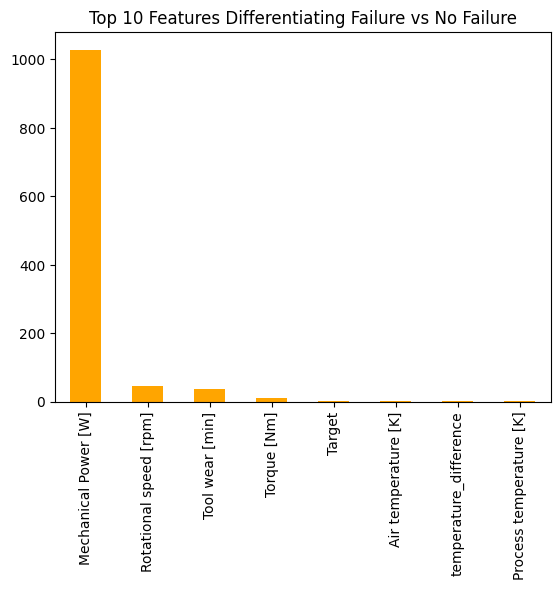

In [14]:
df_encoded = df.copy()
df_encoded['Failure Binary'] = (df_encoded['Failure Type'] != 'No Failure').astype(int)

numeric_df = df_encoded.select_dtypes(include=['number'])
mean_diff = numeric_df.groupby('Failure Binary').mean().T
mean_diff['difference'] = abs(mean_diff[1] - mean_diff[0])  
mean_diff['difference'].sort_values(ascending=False).head(10).plot(kind='bar', color='orange')
plt.title("Top 10 Features Differentiating Failure vs No Failure")
plt.show()


2  What is the distribution of machine types (L, M, H) in the dataset?

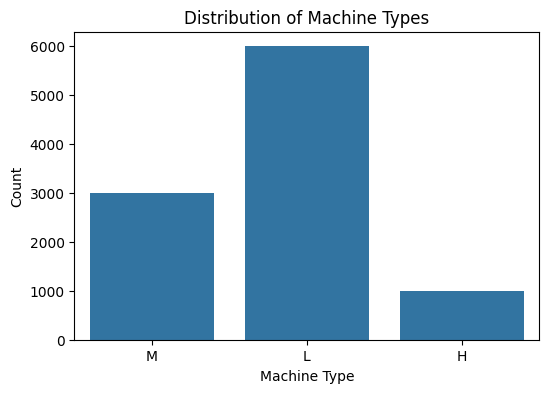

In [15]:
plt.figure(figsize=(6,4))
sns.countplot(x='Type', data=df)
plt.title('Distribution of Machine Types')
plt.xlabel('Machine Type')
plt.ylabel('Count')
plt.show()


3  What is the overall failure rate in the dataset?

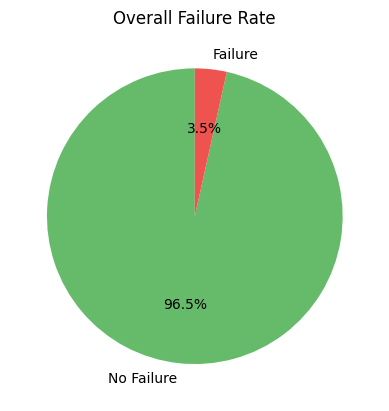

In [16]:
labels = ['No Failure', 'Failure']
counts = [
    (df['Failure Type'] == 'No Failure').sum(),
    (df['Failure Type'] != 'No Failure').sum()
]
plt.pie(counts, labels=labels, autopct='%1.1f%%', colors=['#66bb6a', '#ef5350'], startangle=90)
plt.title('Overall Failure Rate')
plt.show()


4 How does tool wear vary across machine types?

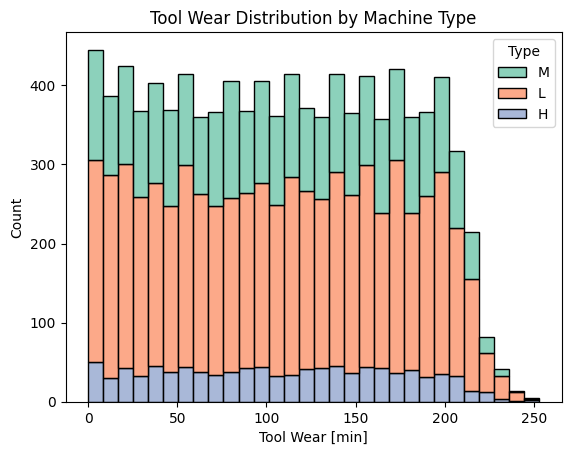

In [17]:
sns.histplot(data=df, x='Tool wear [min]', hue='Type', multiple='stack', palette='Set2', bins=30)
plt.title('Tool Wear Distribution by Machine Type')
plt.xlabel('Tool Wear [min]')
plt.ylabel('Count')
plt.show()


5  What are the counts of each failure type (TWF, HDF, etc.)?


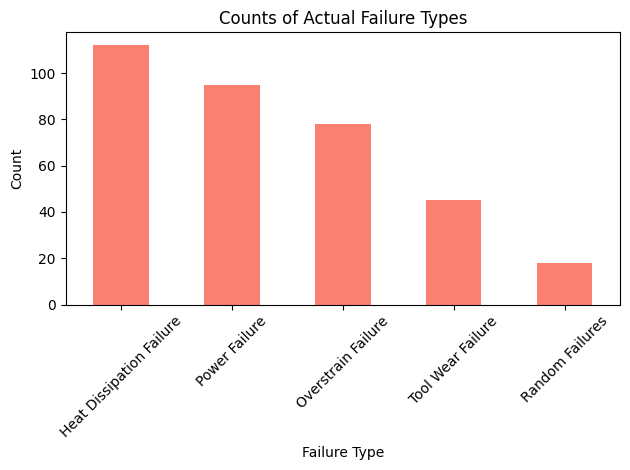

In [18]:
df[df['Failure Type'] != 'No Failure']['Failure Type'].value_counts().plot(kind='bar', color='salmon')
plt.title('Counts of Actual Failure Types')
plt.xlabel('Failure Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


6 Are failures more likely after a certain amount of tool wear time?

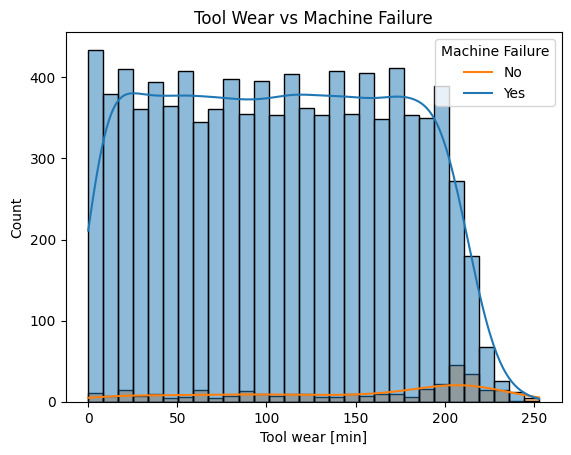

In [19]:

sns.histplot(data=df, x='Tool wear [min]', hue='Target', kde=True, bins=30)
plt.title('Tool Wear vs Machine Failure')
plt.xlabel('Tool wear [min]')
plt.ylabel('Count')
plt.legend(title='Machine Failure', labels=['No', 'Yes'])
plt.show()

7 At what tool wear level should we consider preventive

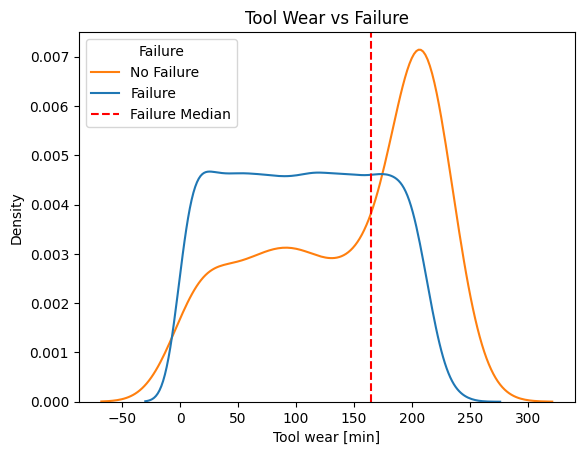

In [20]:
sns.kdeplot(data=df, x='Tool wear [min]', hue='Target', common_norm=False)
plt.axvline(df[df['Target'] == 1]['Tool wear [min]'].median(), color='red', linestyle='--', label='Failure Median')
plt.title('Tool Wear vs Failure')
plt.xlabel('Tool wear [min]')
plt.legend(title='Failure', labels=['No Failure', 'Failure', 'Failure Median'])
plt.show()


8 Can we recommend optimal operating ranges (torque/speed/temp) to reduce failures?


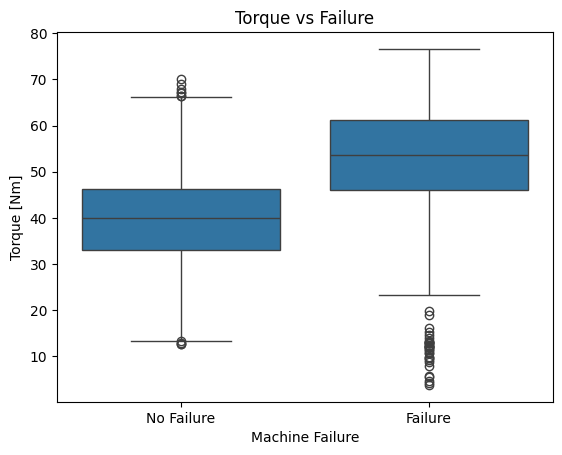

In [21]:
sns.boxplot(data=df, x='Target', y='Torque [Nm]')
plt.title('Torque vs Failure')
plt.xlabel('Machine Failure')
plt.ylabel('Torque [Nm]')
plt.xticks([0, 1], ['No Failure', 'Failure'])
plt.show()


<h2 style="color:#1976d2;">5. Encoding Columns</h2>


In [22]:
df['Type'] = LabelEncoder().fit_transform(df['Type'])
df['Target'] = df['Failure Type'].apply(lambda x: 0 if x == 'No Failure' else 1)


In [23]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type,temperature_difference,Mechanical Power [W]
0,2,298.1,308.6,1551,42.8,0,0,No Failure,10.5,6951.5906
1,1,298.2,308.7,1408,46.3,3,0,No Failure,10.5,6826.7227
2,1,298.1,308.5,1498,49.4,5,0,No Failure,10.4,7749.3875
3,1,298.2,308.6,1433,39.5,7,0,No Failure,10.4,5927.5047
4,1,298.2,308.7,1408,40.0,9,0,No Failure,10.5,5897.8166


In [24]:

df.columns = [str(col).replace('[', '_').replace(']', '_').replace('<', '_') for col in df.columns]


In [25]:
df_failure_only = df[df["Target"] == 1].copy()


<h2 style="color:#1976d2;">7. Splitting Data into Features (X) and Target (y)</h2>


In [26]:
X = df.drop(columns=['Target', 'Failure Type'])
y = df['Target']

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)



<h2 style="color:#1976d2;">6. Feature Scaling</h2>


In [27]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)



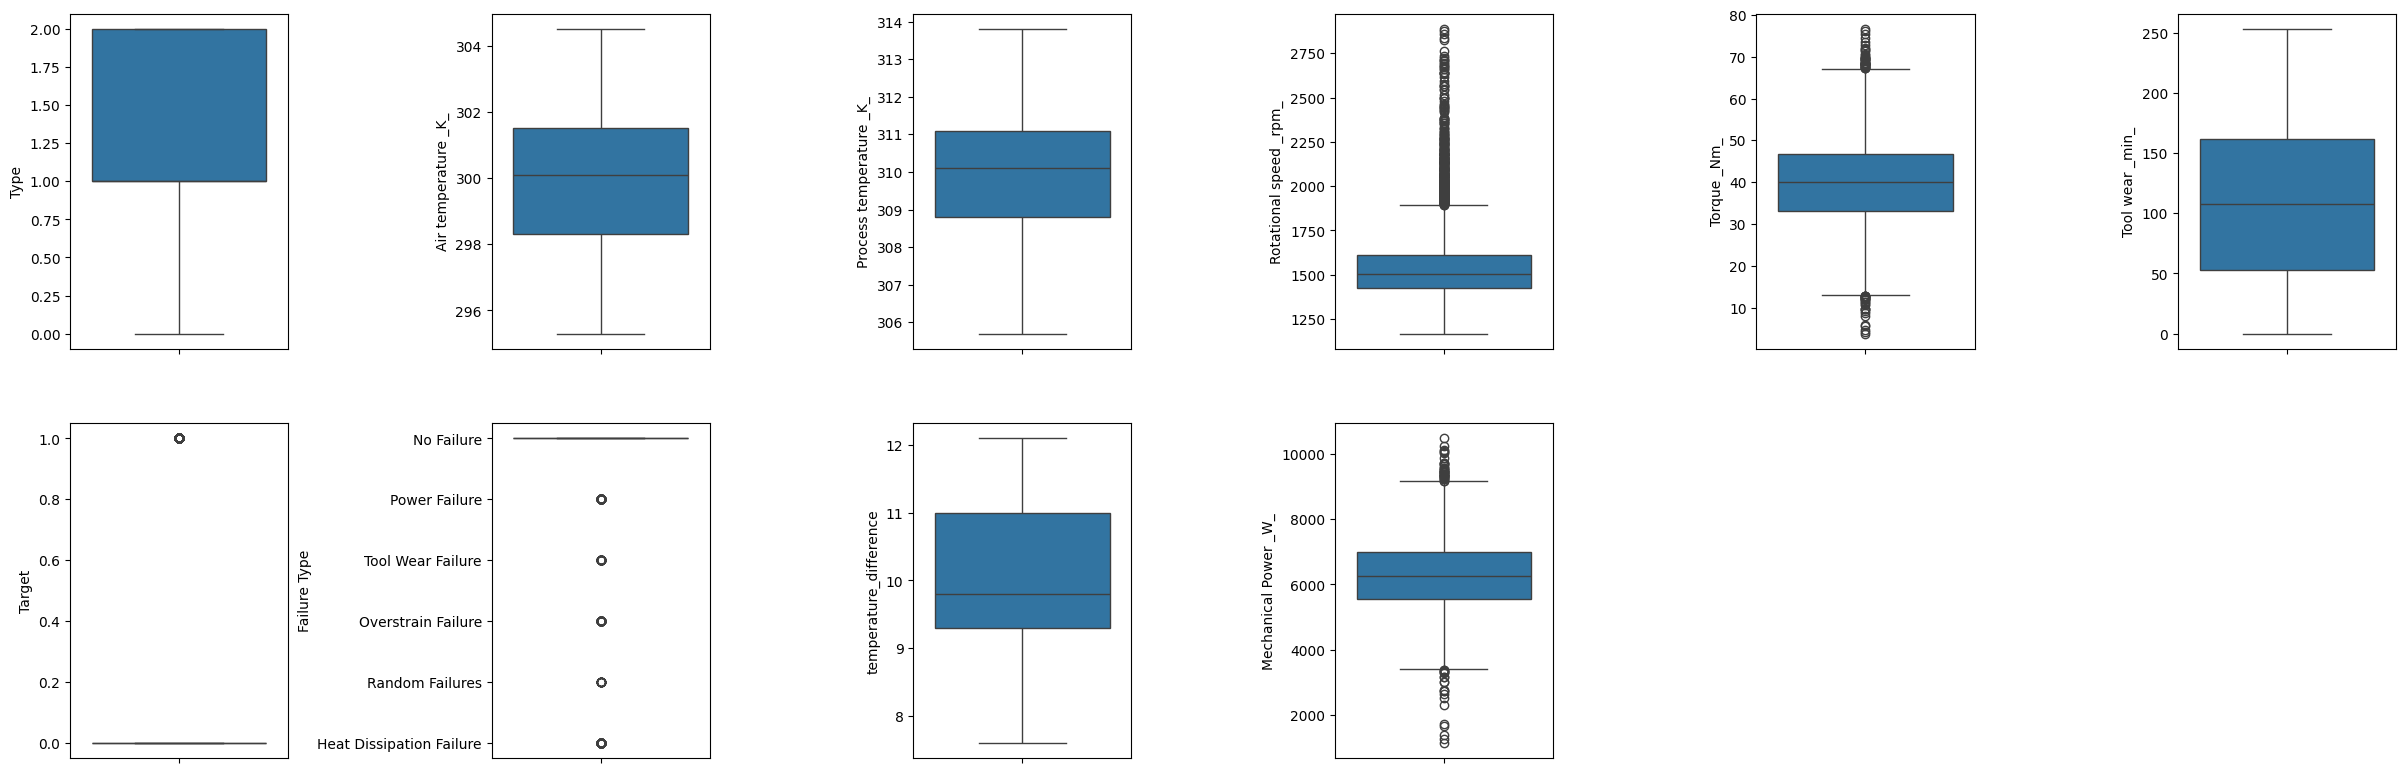

In [28]:
fig, ax = plt.subplots(ncols=6, nrows=6, figsize=(24, 24))
ax = ax.flatten()

for index, col in enumerate(df.columns):
    sns.boxplot(y=col, data=df, ax=ax[index])
    
for i in range(len(df.columns), len(ax)):
    ax[i].set_visible(False)

plt.tight_layout(pad=0.5, w_pad=0.7, h_pad=5.0)
plt.show()

In [29]:
def treat_outliers(df, n=1.5, features=[]):
    for col in features:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - n * IQR
        upper_bound = Q3 + n * IQR
        df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

features = df.columns.tolist()
for col in ['target', 'Failure Type']:
    if col in features:
        features.remove(col)

treat_outliers(df, n=1.5, features=features)


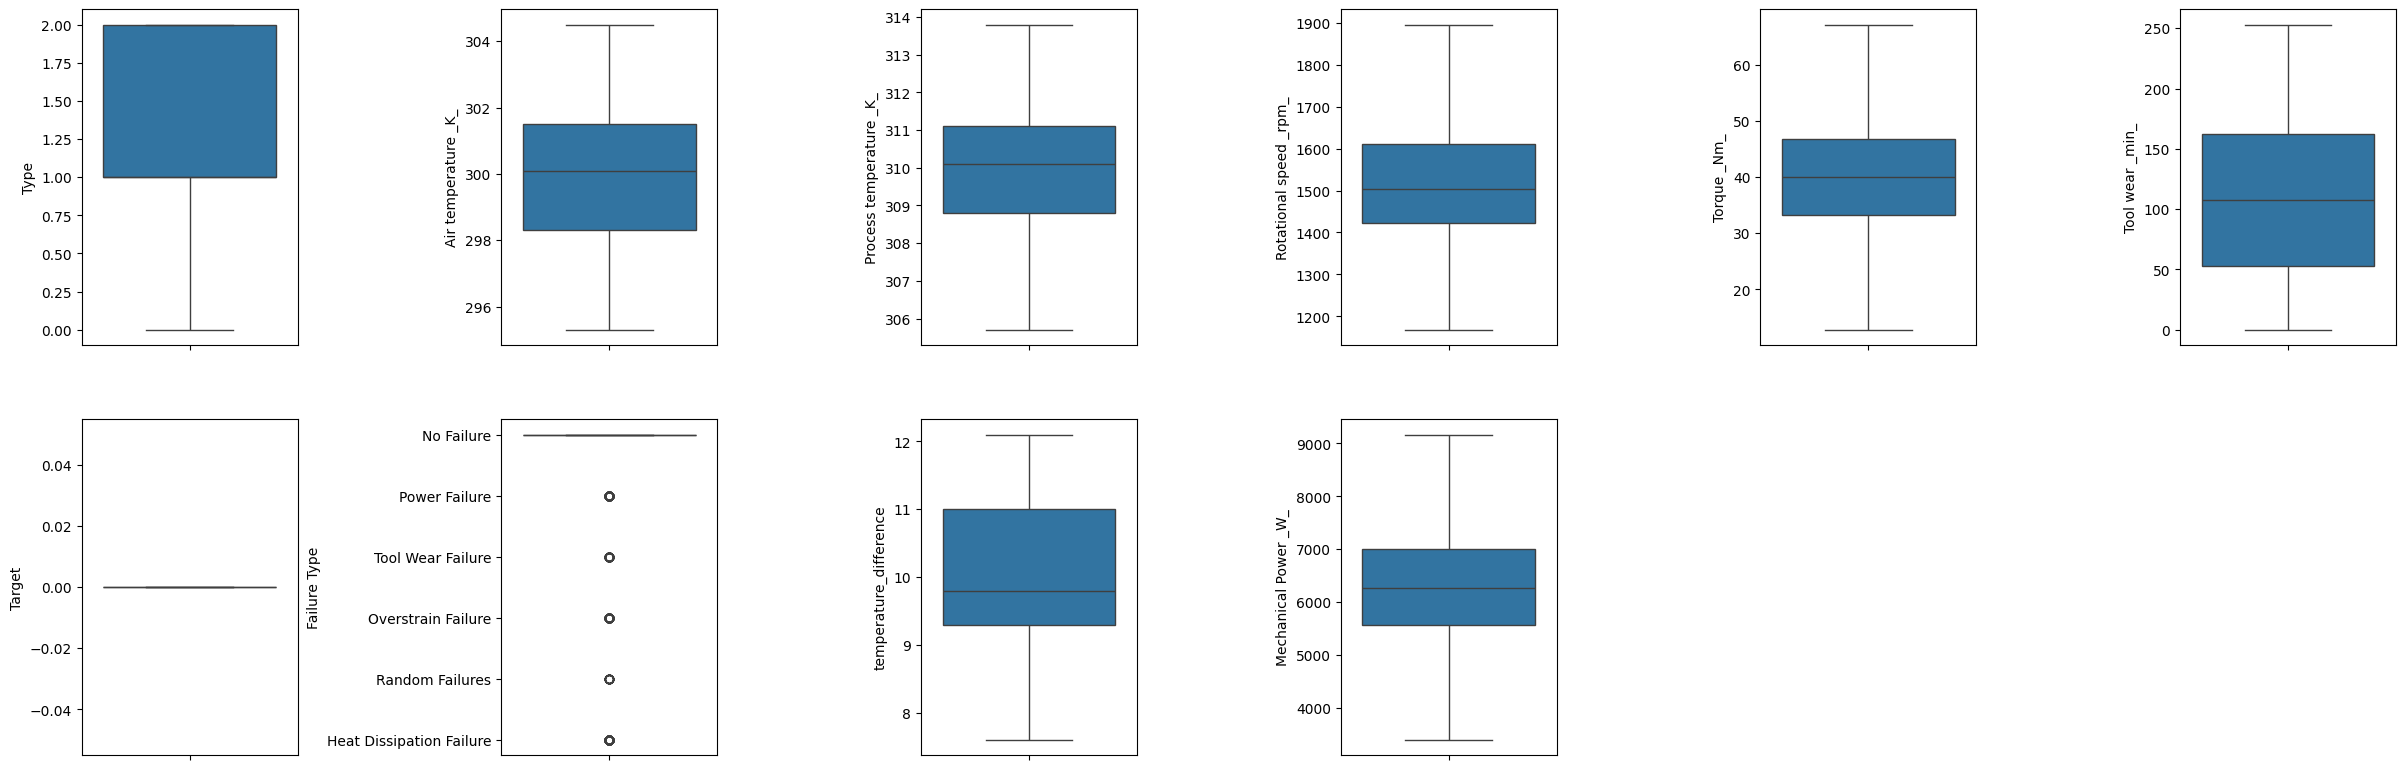

In [30]:
fig, ax = plt.subplots(ncols=6, nrows=6, figsize=(24, 24))
ax = ax.flatten()

for index, col in enumerate(df.columns):
    sns.boxplot(y=col, data=df, ax=ax[index])
    
for i in range(len(df.columns), len(ax)):
    ax[i].set_visible(False)

plt.tight_layout(pad=0.5, w_pad=0.7, h_pad=5.0)
plt.show()

<h2 style="color:#1976d2;">8. Handling Imbalanced Data</h2>


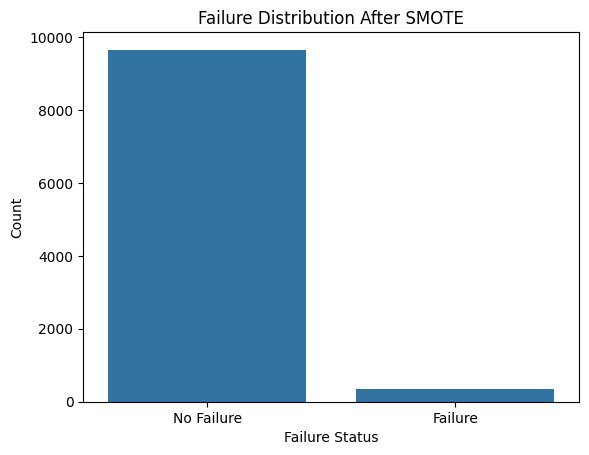

In [31]:
sns.countplot(x=pd.Series(y).map({0: 'No Failure', 1: 'Failure'}))
plt.title("Failure Distribution After SMOTE")
plt.xlabel("Failure Status")
plt.ylabel("Count")
plt.show()


In [32]:
smote = SMOTE(random_state=42)
x, y = smote.fit_resample(x_train, y_train)

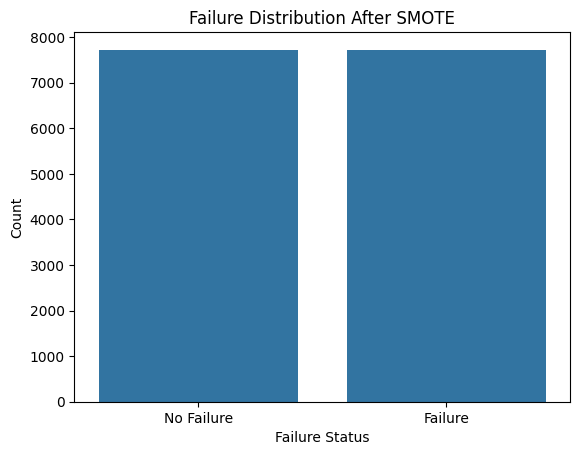

In [33]:
sns.countplot(x=pd.Series(y).map({0: 'No Failure', 1: 'Failure'}))
plt.title("Failure Distribution After SMOTE")
plt.xlabel("Failure Status")
plt.ylabel("Count")
plt.show()


In [34]:
print(df["Target"].value_counts())


Target
0    10000
Name: count, dtype: int64


<h2 style="color:#1976d2;">9. Let's See Which Algorithm Gives Best Accuracy</h2>


In [35]:

models = [
    ("CART", DecisionTreeClassifier(random_state=42)),
    ("RF", RandomForestClassifier(random_state=42)),
    ("XGB", XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42))
]

param_grids = {
    "CART": {
        "max_depth": [3, 6, 9, 12],
        "min_samples_split": [2, 4, 6],
        "min_samples_leaf": [2, 4, 6],
        "max_features": [None, 2, 4]
    },
    "RF": {
        "n_estimators": [100, 200, 300],
        "max_depth": [5, 10, 15],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 3, 5],
        "max_features": ["sqrt", "log2", None]
    },
    "XGB": {
        "n_estimators": [100, 200],
        "max_depth": [3, 6, 9],
        "learning_rate": [0.01, 0.1, 0.2],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0]
    }
}

In [36]:
best_models = []
best_scores = {}

for model_name, model in models:
    param_grid = param_grids.get(model_name, {})

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=5,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=-1
    )

    grid_search.fit(x_train, y_train)
    best_models.append((model_name, grid_search.best_estimator_))
    best_scores[model_name] = grid_search.best_score_

/home/mo/.local/lib/python3.10/site-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,
/home/mo/miniconda/envs/mo3/lib/python3.10/site-packages/xgboost/training.py:183: UserWarning: [19:16:59] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/mo/miniconda/envs/mo3/lib/python3.10/site-packages/xgboost/training.py:183: UserWarning: [19:16:59] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/mo/miniconda/envs/mo3/lib/python3.10/site-packages/xgboost/training.py:183: UserWarning: [19:16:59] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/mo/miniconda/envs/mo3/lib/python3.10/site-packages/xgboost/training.py:183: UserWarning: [19:16:59] W

<h2 style="color:#1976d2;">10. Select the Best Model </h2>


In [37]:
top_3_models = sorted(best_scores, key=best_scores.get, reverse=True)[:3]
top_3_models_names = [m for m in top_3_models]

print("Top 3 models selected for VotingClassifier:")
for name in top_3_models_names:
    print(name, "with accuracy:", best_scores[name])

voting_clf = VotingClassifier(
    estimators=[(name, dict(best_models)[name]) for name in top_3_models_names],
    voting='soft'
)

voting_clf.fit(x_train, y_train)

Top 3 models selected for VotingClassifier:
RF with accuracy: 0.988875
CART with accuracy: 0.9877499999999999
XGB with accuracy: 0.9865


VotingClassifier(estimators=[('RF',
                              RandomForestClassifier(max_depth=15,
                                                     max_features=None,
                                                     min_samples_leaf=3,
                                                     random_state=42)),
                             ('CART',
                              DecisionTreeClassifier(max_depth=6,
                                                     min_samples_leaf=6,
                                                     random_state=42)),
                             ('XGB',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=1.0, device=None,
                                            e...
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=6,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=100, n_jobs=None,
                                            num_parallel_tree=None, ...))],
                 voting='soft')

Train Accuracy (CV mean): 0.9929062499999999
Test Accuracy: 0.989

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99      1930
           1       0.94      0.73      0.82        70

    accuracy                           0.99      2000
   macro avg       0.97      0.86      0.91      2000
weighted avg       0.99      0.99      0.99      2000



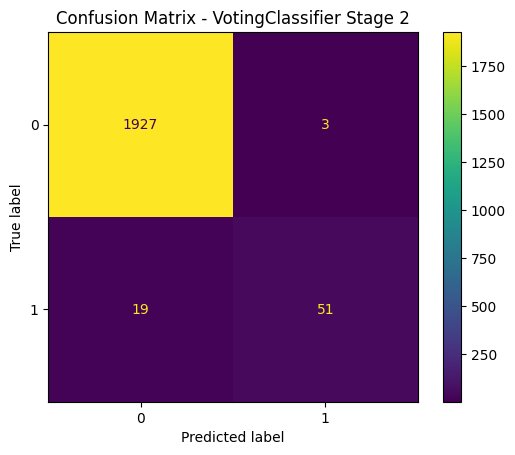

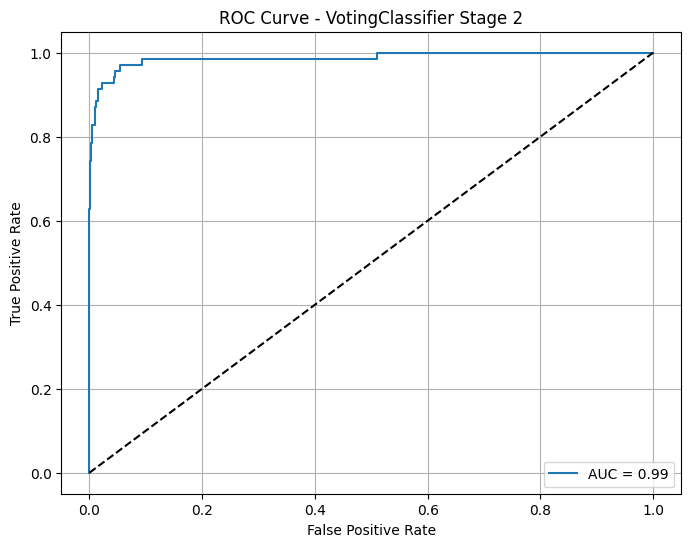

In [38]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    voting_clf, x_train, y_train_enc,
    cv=skf, scoring="accuracy", return_train_score=True
)

voting_clf.fit(x_train, y_train_enc)
y_pred = voting_clf.predict(x_test)
accuracy_test = accuracy_score(y_test_enc, y_pred)

print("Train Accuracy (CV mean):", scores["train_score"].mean())
print("Test Accuracy:", accuracy_test)

print("\nClassification Report:\n", classification_report(
    y_test_enc, y_pred, target_names=[str(c) for c in le.classes_]
))

ConfusionMatrixDisplay.from_predictions(
    y_test_enc, y_pred, display_labels=[str(c) for c in le.classes_]
)
plt.title("Confusion Matrix - VotingClassifier Stage 2")
plt.show()

y_proba = voting_clf.predict_proba(x_test)

if len(le.classes_) == 2:
    fpr, tpr, _ = roc_curve(y_test_enc, y_proba[:,1])
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(8,6))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
    plt.plot([0,1], [0,1], 'k--')
    plt.title("ROC Curve - VotingClassifier Stage 2")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
else:
    y_test_bin = label_binarize(y_test_enc, classes=np.arange(len(le.classes_)))
    plt.figure(figsize=(8,6))
    for i, class_name in enumerate(le.classes_):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{class_name} (AUC = {roc_auc:.2f})")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title("ROC Curve - VotingClassifier Stage 2")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()


<h2 style="color:#1976d2;">10. Save Best Model </h2>


In [39]:
joblib.dump(voting_clf, "stage1_voting_classifier.pkl")

['stage1_voting_classifier.pkl']

<h2 style="color:#1976d2;">11. Preprocessing for Stage 2 (Second Model)</h2>


In [40]:
df_failure_only.tail(10)

,Type,Air temperature _K_,Process temperature _K_,Rotational speed _rpm_,Torque _Nm_,Tool wear _min_,Target,Failure Type,temperature_difference,Mechanical Power _W_
9654,1,299.1,310.0,1367,56.3,203,1,Overstrain Failure,10.9,8059.4523
9659,1,298.9,309.8,1287,61.9,216,1,Overstrain Failure,10.9,8342.5307
9663,1,299.1,310.1,1435,48.8,229,1,Overstrain Failure,11.0,7333.3150
9664,1,299.1,310.2,1317,54.8,231,1,Overstrain Failure,11.1,7557.7923
9667,1,299.2,310.3,1352,48.9,238,1,Overstrain Failure,11.1,6923.3162
9758,1,298.6,309.8,2271,16.2,218,1,Tool Wear Failure,11.2,3852.6607
9764,1,298.5,309.5,1294,66.7,12,1,Power Failure,11.0,9038.3411
9822,1,298.5,309.4,1360,60.9,187,1,Overstrain Failure,10.9,8673.3090
9830,1,298.3,309.3,1337,56.1,206,1,Overstrain Failure,11.0,7854.5785
9974,1,298.6,308.2,1361,68.2,172,1,Power Failure,9.6,9720.1086


In [41]:
df_failure_only['Failure Type'].unique()


array(['Power Failure', 'Tool Wear Failure', 'Overstrain Failure',
       'Random Failures', 'Heat Dissipation Failure'], dtype=object)

In [42]:
print(len(df_failure_only))

348


In [43]:
X2 = df_failure_only.drop(columns=['Target', 'Failure Type'])
y2 = df_failure_only['Failure Type']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

skf2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [44]:
scaler = StandardScaler()
X2_train_scaled = scaler.fit_transform(X2_train)
X2_test_scaled = scaler.transform(X2_test)

In [45]:
le2 = LabelEncoder()
y2_train = le2.fit_transform(y2_train)
y2_test = le2.transform(y2_test)

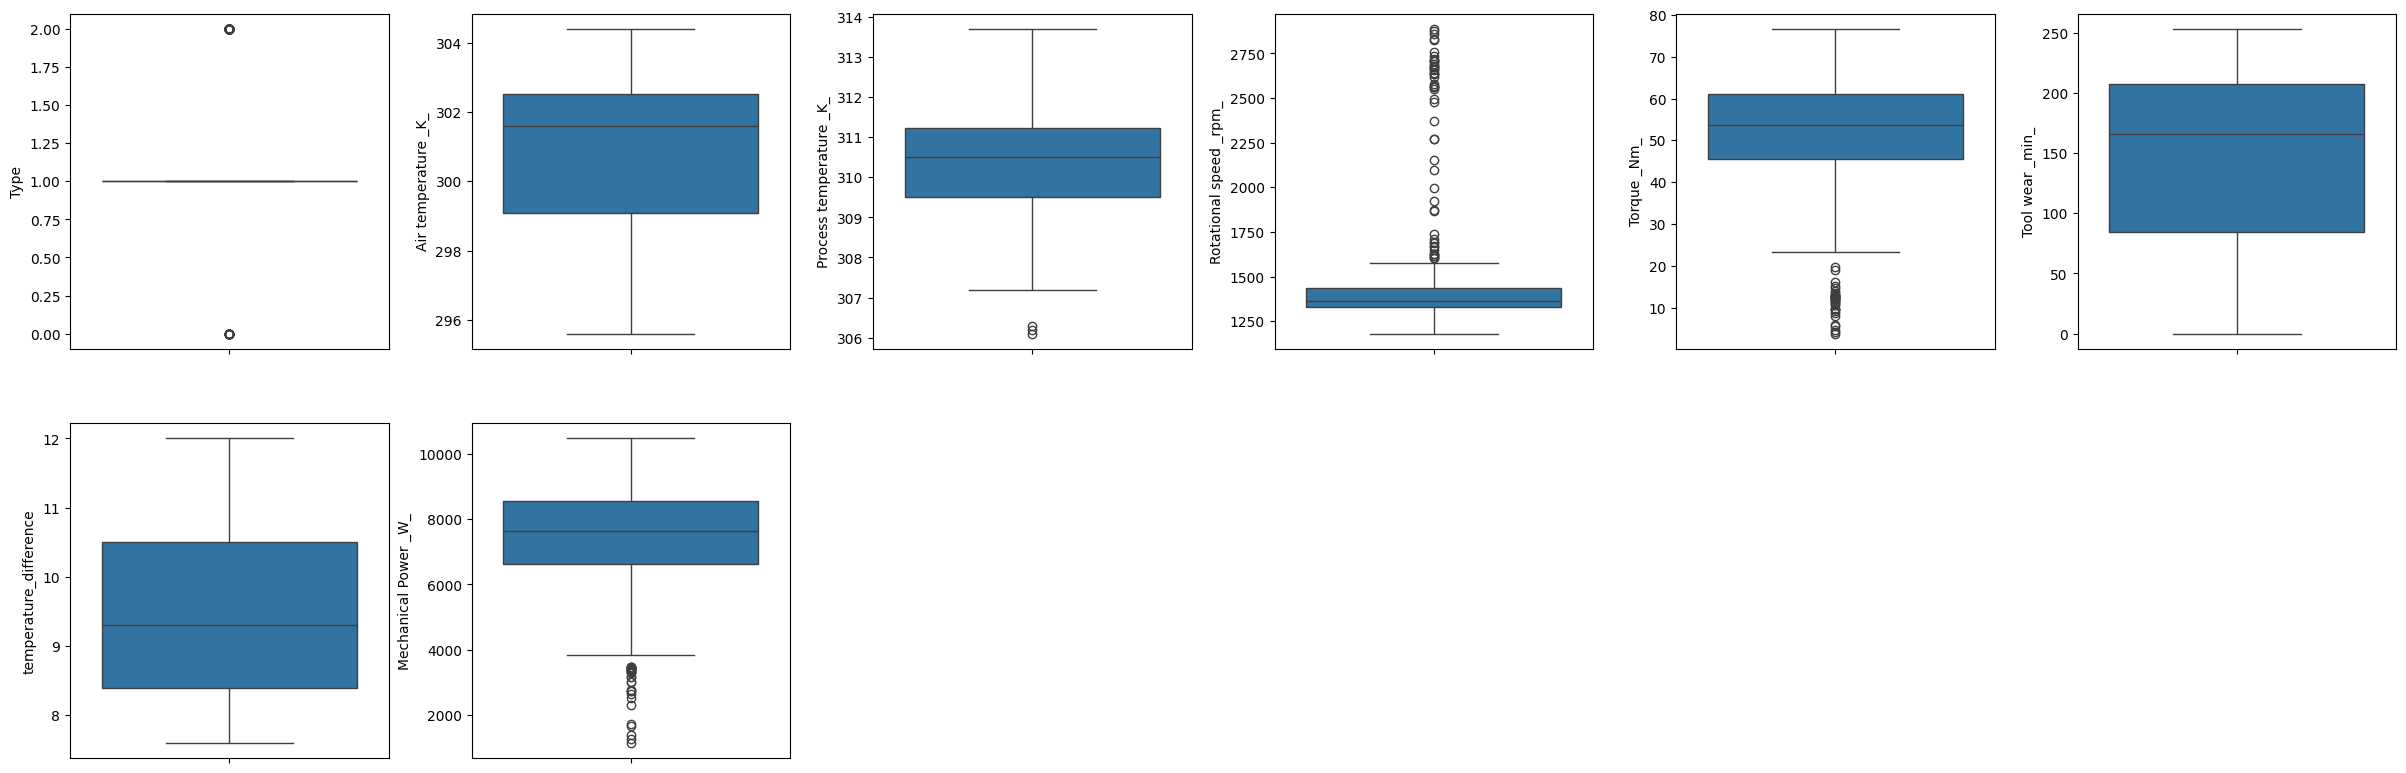

In [46]:
fig, ax = plt.subplots(ncols=6, nrows=6, figsize=(24, 24))
ax = ax.flatten()

for index, col in enumerate(X2.columns):
    sns.boxplot(y=col, data=X2, ax=ax[index])
    
for i in range(len(X2.columns), len(ax)):
    ax[i].set_visible(False)

plt.tight_layout(pad=0.5, w_pad=0.7, h_pad=5.0)
plt.show()


In [47]:
def treat_outliers(df, n=1.5, features=[]):
    for col in features:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - n * IQR
        upper_bound = Q3 + n * IQR
        df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

features2 = X2.columns.tolist()
treat_outliers(X2, n=1.5, features=features2)


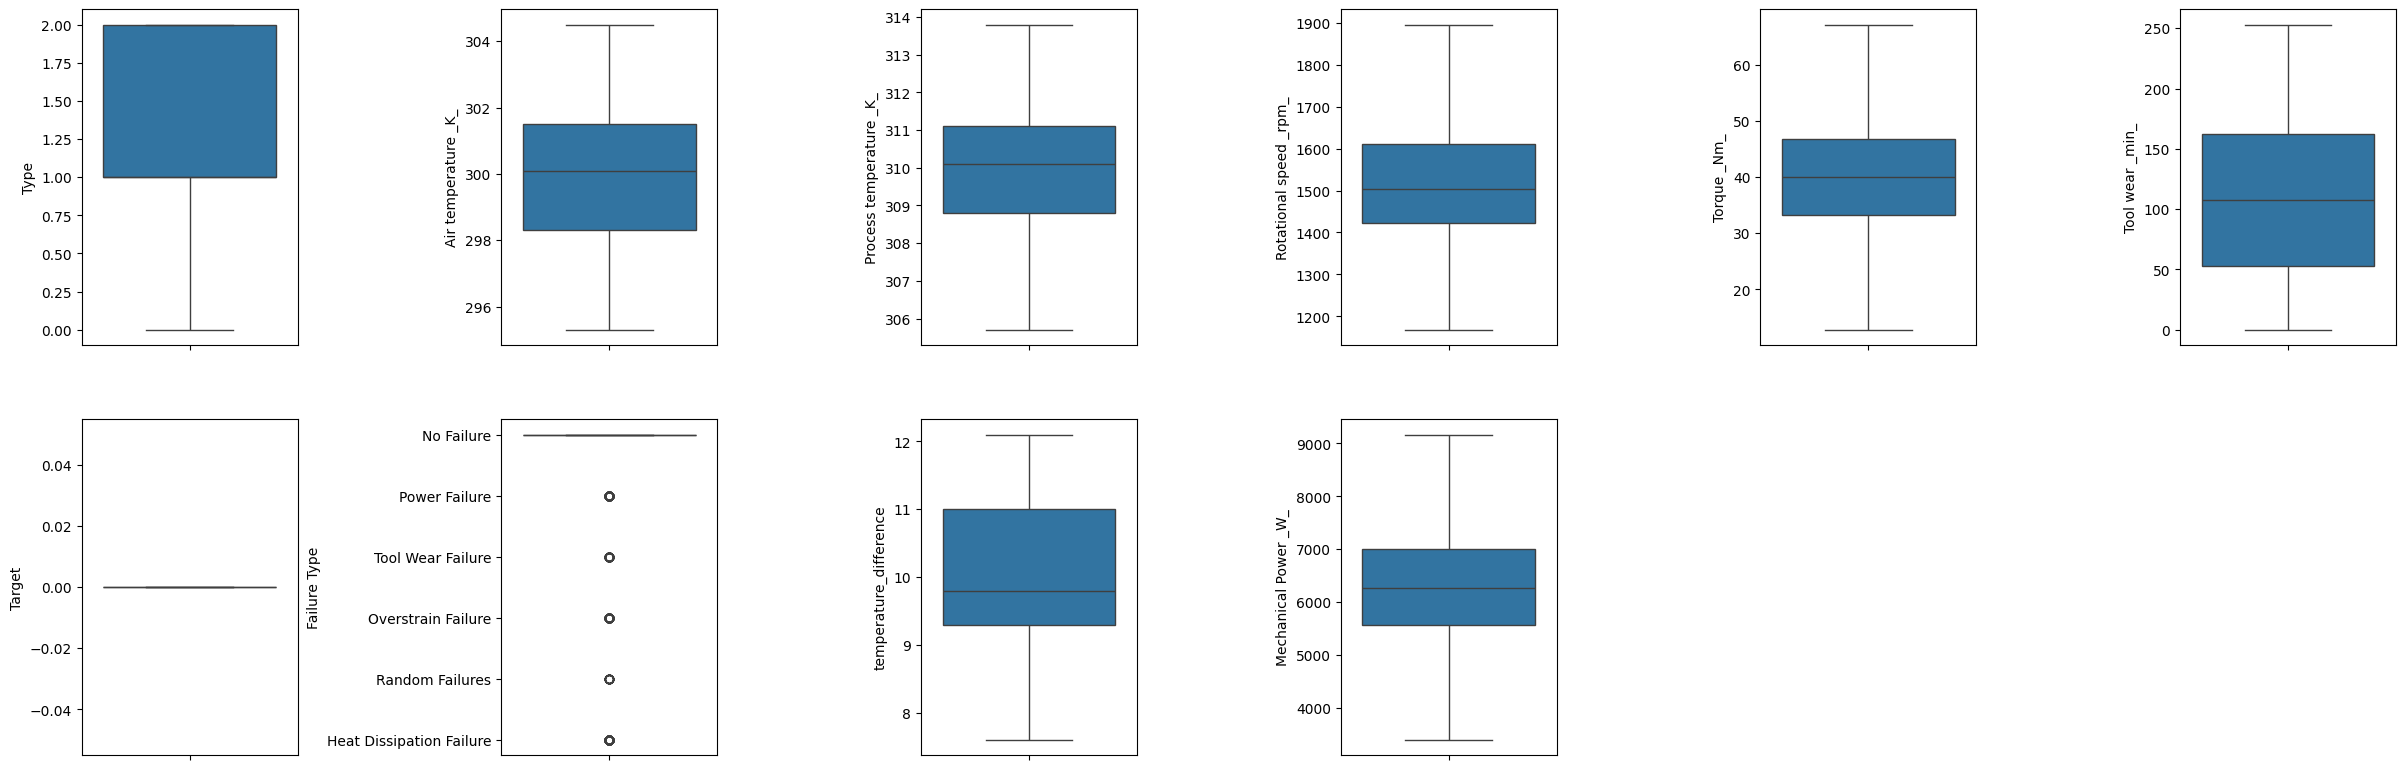

In [48]:
fig, ax = plt.subplots(ncols=6, nrows=6, figsize=(24, 24))
ax = ax.flatten()

for index, col in enumerate(df.columns):
    sns.boxplot(y=col, data=df, ax=ax[index])
    
for i in range(len(df.columns), len(ax)):
    ax[i].set_visible(False)

plt.tight_layout(pad=0.5, w_pad=0.7, h_pad=5.0)
plt.show()

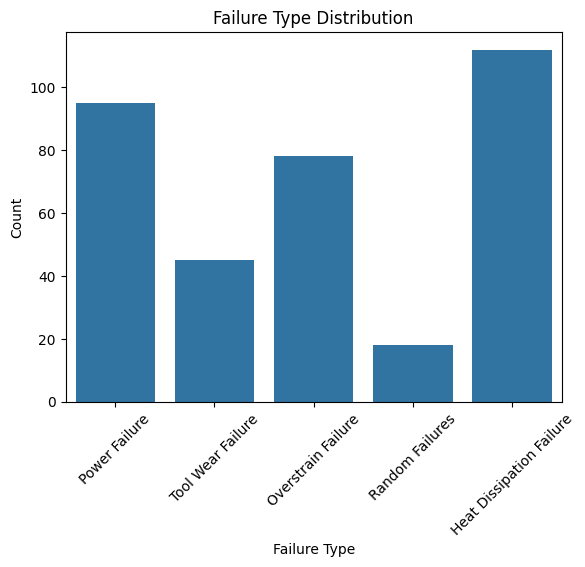

In [49]:
sns.countplot(x=y2)
plt.title("Failure Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Count")
plt.xticks(rotation=45)  
plt.show()

<h2 style="color:#1976d2;"> Handling Imbalanced Data</h2>


In [50]:
smote2 = SMOTE(random_state=42)
X2_train, y2_train = smote2.fit_resample(X2_train, y2_train)

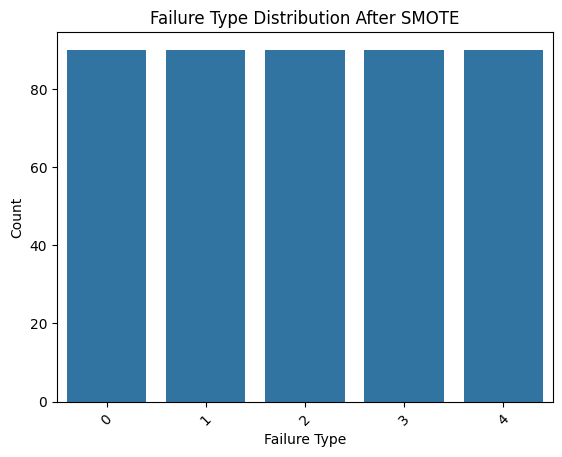

In [51]:
sns.countplot(x=y2_train)
plt.title("Failure Type Distribution After SMOTE")
plt.xlabel("Failure Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

In [52]:
models2 = [
    ("CART", DecisionTreeClassifier(random_state=42)),
    ("RF", RandomForestClassifier(random_state=42)),
    ("XGB", XGBClassifier( eval_metric="logloss", random_state=42))
]

param_grids2 = {
    "CART": {
        "max_depth": [3, 6, 9, 12],
        "min_samples_split": [2, 4, 6],
        "min_samples_leaf": [2, 4, 6],
        "max_features": [None, 2, 4]
    },
    "RF": {
        "n_estimators": [100, 200, 300],
        "max_depth": [5, 10, 15],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 3, 5],
        "max_features": ["sqrt", "log2", None]
    },
    "XGB": {
        "n_estimators": [100, 200],
        "max_depth": [3, 6, 9],
        "learning_rate": [0.01, 0.1, 0.2],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0]
    }
}


In [53]:
best_models2 = []
best_scores2 = {}

for model_name, model in models2:
    param_grid = param_grids2.get(model_name, {})

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=5,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=-1
    )

    grid_search.fit(X2_train, y2_train)
    best_models2.append((model_name, grid_search.best_estimator_))
    best_scores2[model_name] = grid_search.best_score_


/home/mo/.local/lib/python3.10/site-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


In [54]:
top_3_models2 = sorted(best_scores2, key=best_scores2.get, reverse=True)[:3]
top_3_models_names2 = [m for m in top_3_models2]

print("Top 3 models selected for Stage 2 VotingClassifier:")
for name in top_3_models_names2:
    print(name, "with accuracy:", best_scores2[name])

voting_clf2 = VotingClassifier(
    estimators=[(name, dict(best_models2)[name]) for name in top_3_models_names2],
    voting='soft'
)

voting_clf2.fit(X2_train, y2_train)


Top 3 models selected for Stage 2 VotingClassifier:
RF with accuracy: 0.9866666666666667
XGB with accuracy: 0.9800000000000001
CART with accuracy: 0.9644444444444444


VotingClassifier(estimators=[('RF',
                              RandomForestClassifier(max_depth=15,
                                                     random_state=42)),
                             ('XGB',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=0.8, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric='logloss',
                                            feature_types=None,
                                            feature_weights=None, gamm...
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=3,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=100, n_jobs=None,
                                            num_parallel_tree=None, ...)),
                             ('CART',
                              DecisionTreeClassifier(max_depth=9,
                                                     max_features=4,
                                                     min_samples_leaf=2,
                                                     random_state=42))],
                 voting='soft')

Train Accuracy (CV mean): 1.0
Test Accuracy: 0.9285714285714286

Classification Report:
                           precision    recall  f1-score   support

Heat Dissipation Failure       0.96      1.00      0.98        22
      Overstrain Failure       0.87      0.81      0.84        16
           Power Failure       1.00      1.00      1.00        19
         Random Failures       0.60      0.75      0.67         4
       Tool Wear Failure       1.00      0.89      0.94         9

                accuracy                           0.93        70
               macro avg       0.88      0.89      0.88        70
            weighted avg       0.93      0.93      0.93        70



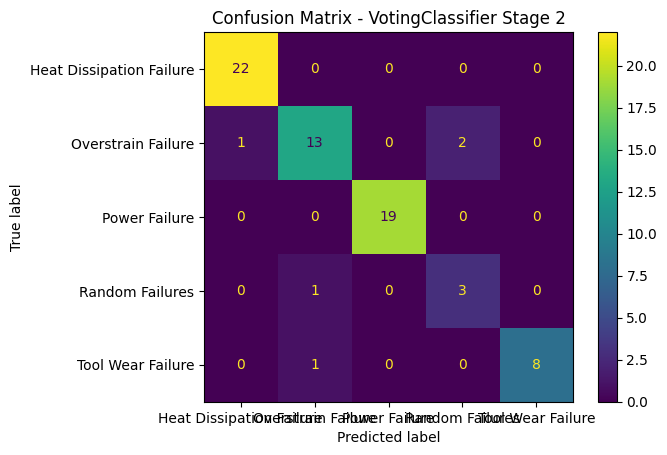

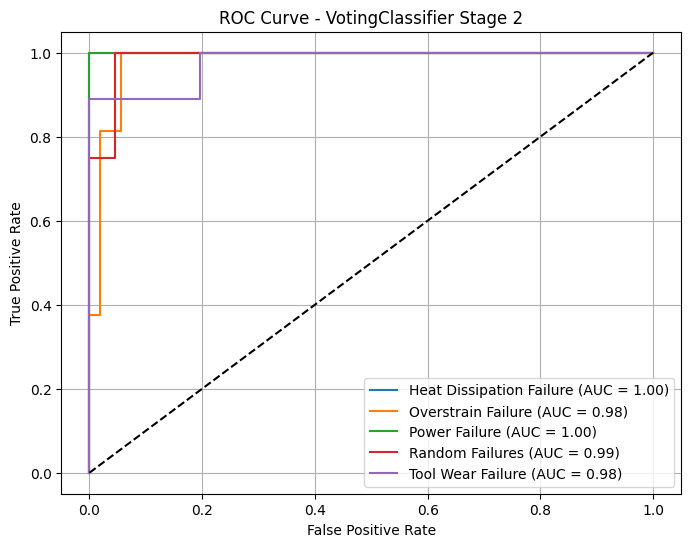

In [55]:
scores = cross_validate(
    voting_clf2, X2_train, y2_train,
    cv=skf2, scoring="accuracy", return_train_score=True
)

voting_clf2.fit(X2_train, y2_train)

y2_pred = voting_clf2.predict(X2_test)
accuracy_test = accuracy_score(y2_test, y2_pred)

print("Train Accuracy (CV mean):", scores["train_score"].mean())
print("Test Accuracy:", accuracy_test)

print("\nClassification Report:\n", classification_report(
    y2_test, y2_pred, target_names=[str(c) for c in le2.classes_]
))

ConfusionMatrixDisplay.from_predictions(
    y2_test, y2_pred, display_labels=[str(c) for c in le2.classes_]
)
plt.title("Confusion Matrix - VotingClassifier Stage 2")
plt.show()

y2_proba = voting_clf2.predict_proba(X2_test)
y2_test_bin = label_binarize(y2_test, classes=np.arange(len(le2.classes_)))
plt.figure(figsize=(8,6))
for i, class_name in enumerate(le2.classes_):
    fpr, tpr, _ = roc_curve(y2_test_bin[:, i], y2_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_name} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.title("ROC Curve - VotingClassifier Stage 2")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [56]:
y2_pred = voting_clf2.predict(X2_test)
accuracy2 = accuracy_score(y2_test, y2_pred)
print("Stage 2 VotingClassifier Test Accuracy:", accuracy2)

joblib.dump(voting_clf2, "stage2_voting_classifier.pkl")


Stage 2 VotingClassifier Test Accuracy: 0.9285714285714286


['stage2_voting_classifier.pkl']